# Part 1 — Time-series diagnostics of daily PM2.5

This notebook examines the temporal behaviour of the cleaned station-day panel. It uses the
**development partition only**: the reserved chronological holdout recorded in
`results/future_holdout.json` is excluded from every calculation here.

The panel is irregular, so conventional time-series diagnostics are restricted to each station's
**longest uninterrupted daily segment**. Autocorrelation (ACF) and partial autocorrelation (PACF)
are reported for stations whose longest run reaches 14 days; ADF, KPSS and Ljung–Box tests are
reported only where the run reaches 30 days. A per-station OLS trend slope is estimated on the same
uninterrupted segments.

**Prerequisite.** Run `python -m pm25_project.cli audit` (and `folds`) with the source files
described in `data/manifest.yaml` before re-executing this notebook.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "configs" / "project.yaml").is_file():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from config import DATA_PROCESSED, RESULTS_DIR
from pm25_project.temporal_diagnostics import temporal_table

%matplotlib inline
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

panel = pd.read_csv(DATA_PROCESSED / "cleaned_daily.csv", parse_dates=["timestamp"])
panel["timestamp"] = pd.to_datetime(panel["timestamp"], utc=True)
partition = json.loads((RESULTS_DIR / "future_holdout.json").read_text(encoding="utf-8"))
development = panel.iloc[partition["development_indices"]].copy().sort_values(["station_id", "timestamp"])

print(f"Cleaned panel: {len(panel):,} station-days, {panel.station_id.nunique()} stations, "
      f"{panel.timestamp.dt.normalize().nunique():,} dates")
print(f"Development partition: {len(development):,} station-days, "
      f"{development.station_id.nunique()} stations, "
      f"{development.timestamp.min().date()} to {development.timestamp.max().date()}")
print(f"Reserved holdout: {partition['n_holdout_dates']} dates from {partition['holdout_start'][:10]} "
      f"(status: {partition['status']})")

Cleaned panel: 40,983 station-days, 95 stations, 2,299 dates
Development partition: 30,651 station-days, 73 stations, 2016-11-25 to 2024-12-07
Reserved holdout: 460 dates from 2024-12-08 (status: reserved)


## 1. Daily coverage per station

A station's coverage is the number of distinct observation days and the length of its longest run of
consecutive calendar days. Gaps break a run.

In [2]:
def longest_run_dates(dates: pd.Series) -> pd.DatetimeIndex:
    days = pd.DatetimeIndex(sorted(pd.to_datetime(dates, utc=True).dt.normalize().unique()))
    if len(days) == 0:
        return days
    breaks = np.flatnonzero(np.diff(days.values).astype("timedelta64[D]").astype(int) != 1) + 1
    best = max(np.split(np.arange(len(days)), breaks), key=len)
    return days[best]


coverage_rows, segment_frames = [], []
for station, group in development.groupby("station_id", sort=True):
    run = longest_run_dates(group["timestamp"])
    coverage_rows.append({"station_id": station, "n_days": int(group["timestamp"].dt.normalize().nunique()),
                          "longest_run_days": int(len(run))})
    segment_frames.append(group[group["timestamp"].dt.normalize().isin(run)])

coverage = pd.DataFrame(coverage_rows).sort_values(["longest_run_days", "n_days"], ascending=False)
segments = pd.concat(segment_frames, ignore_index=True)

n_stations = len(coverage)
n_acf = int((coverage.longest_run_days >= 14).sum())
n_formal = int((coverage.longest_run_days >= 30).sum())
print(f"Stations: {n_stations}")
print(f"Longest run >= 14 days (ACF/PACF reported): {n_acf}")
print(f"Longest run >= 30 days (ADF/KPSS/Ljung-Box reported): {n_formal}")
print(f"Median longest run: {coverage.longest_run_days.median():.0f} days; "
      f"maximum: {coverage.longest_run_days.max()} days")
coverage.head(10).reset_index(drop=True)

Stations: 73
Longest run >= 14 days (ACF/PACF reported): 63
Longest run >= 30 days (ADF/KPSS/Ljung-Box reported): 6
Median longest run: 17 days; maximum: 32 days


,station_id,n_days,longest_run_days
0,MEDITERRÁNEO::36.841330::-2.446720,708,32
1,LA ALJORRA::37.693611::-1.064722,169,32
2,VALÈNCIA-CENTRE::39.448330::-0.376470,210,31
3,MOLINA DE SEGURA::38.057300::-1.204700,149,31
4,VALÈNCIA - MOLÍ DEL SOL::39.481100::-0.408300,304,30
5,VALÈNCIA OLIVERETA::39.469220::-0.406050,205,30
6,TORRENT-EL VEDAT::39.425280::-0.482500,89,29
7,Perafort::41.193604::1.236701,336,28
8,GRANADA - NORTE::37.196100::-3.612660,697,24
9,PALACIO CONGRESOS::37.165680::-3.600100,370,24


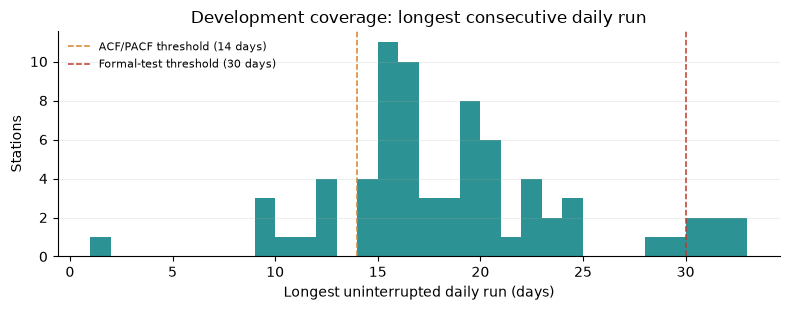

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(coverage.longest_run_days, bins=range(1, int(coverage.longest_run_days.max()) + 2),
        color="#087F80", alpha=0.85)
ax.axvline(14, color="#D9822B", ls="--", lw=1.1, label="ACF/PACF threshold (14 days)")
ax.axvline(30, color="#C0392B", ls="--", lw=1.1, label="Formal-test threshold (30 days)")
ax.set(xlabel="Longest uninterrupted daily run (days)", ylabel="Stations",
       title="Development coverage: longest consecutive daily run")
ax.legend(frameon=False, fontsize=8)
ax.grid(axis="y", alpha=0.2)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

## 2. ACF, PACF and stationarity tests

`temporal_table` is applied to the extracted uninterrupted segments. Because every segment is daily and
gap-free, lag 1 is one day and lag 7 is one week. Stations whose longest run is shorter than 14 days
receive no autocorrelation estimate; the formal tests are undefined below 30 days.

In [4]:
diagnostics = temporal_table(segments)
diagnostics["longest_run_days"] = diagnostics.node_id.map(coverage.set_index("station_id")["longest_run_days"])
estimable = diagnostics.loc[(diagnostics.longest_run_days >= 14) & diagnostics.acf_lag1.notna()].copy()
formal = diagnostics.loc[(diagnostics.longest_run_days >= 30) & diagnostics.adf_p.notna()].copy()

print(f"Stations with an ACF/PACF estimate: {len(estimable)}")
print(f"Stations with ADF/KPSS/Ljung-Box results: {len(formal)}")
estimable[["node_id", "n_records", "t_min", "t_max", "acf_lag1", "acf_lag7", "pacf_lag1"]].head(12).reset_index(drop=True)

Stations with an ACF/PACF estimate: 63
Stations with ADF/KPSS/Ljung-Box results: 6


,node_id,n_records,t_min,t_max,acf_lag1,acf_lag7,pacf_lag1
0,AIX CENTRE ECOLE ART::43.530285::5.440912,14,2024-07-07 00:00:00+00:00,2024-07-20 00:00:00+00:00,0.331364,0.279107,0.291228
1,ALBALAT DELS TARONGERS::39.705278::-0.336667,16,2019-03-15 00:00:00+00:00,2019-03-30 00:00:00+00:00,0.422981,0.501806,0.411709
2,ALCORA::40.051944::-0.189722,16,2017-06-05 00:00:00+00:00,2017-06-20 00:00:00+00:00,0.297368,0.031575,0.233474
3,ALGAR DE PALÀNCIA::39.782222::-0.359167,16,2019-03-15 00:00:00+00:00,2019-03-30 00:00:00+00:00,0.596083,0.399220,0.531215
4,ALMASSORA-C. P. OCHANDO::39.945278::-0.056389,16,2019-03-15 00:00:00+00:00,2019-03-30 00:00:00+00:00,0.298848,0.327428,0.298664
5,BENICASSIM::40.062222::0.072778,16,2017-06-05 00:00:00+00:00,2017-06-20 00:00:00+00:00,0.512336,0.371212,0.353081
6,BURRIANA::39.892222::-0.065000,16,2019-03-15 00:00:00+00:00,2019-03-30 00:00:00+00:00,0.411118,0.041110,0.408477
7,Barcelona - Porta - Can Dragó::41.431949::2.18...,14,2024-07-31 00:00:00+00:00,2024-08-13 00:00:00+00:00,0.330777,-0.096582,0.325790
8,CAMPAMENTO::36.179430::-5.376970,15,2024-08-16 00:00:00+00:00,2024-08-30 00:00:00+00:00,0.698925,-0.706241,0.688214
9,CAMPANILLAS CIFA::36.727850::-4.560950,22,2023-09-23 00:00:00+00:00,2023-10-14 00:00:00+00:00,0.804247,0.527597,0.655503


In [5]:
formal[["node_id", "n_records", "ljung_box_p", "adf_p", "kpss_p", "trend_slope_per_day", "trend_pval"]].reset_index(drop=True)

,node_id,n_records,ljung_box_p,adf_p,kpss_p,trend_slope_per_day,trend_pval
0,LA ALJORRA::37.693611::-1.064722,32,0.005338,0.096933,0.1,0.064767,0.254018
1,MEDITERRÁNEO::36.841330::-2.446720,32,0.971001,0.000006,0.1,0.002711,0.938653
2,MOLINA DE SEGURA::38.057300::-1.204700,31,0.043274,0.020009,0.1,0.083888,0.215308
3,VALÈNCIA - MOLÍ DEL SOL::39.481100::-0.408300,30,0.219778,0.161533,0.1,0.262228,0.128998
4,VALÈNCIA OLIVERETA::39.469220::-0.406050,30,0.097793,0.230974,0.1,0.078592,0.329340
5,VALÈNCIA-CENTRE::39.448330::-0.376470,31,0.005626,0.358802,0.1,0.067158,0.238276


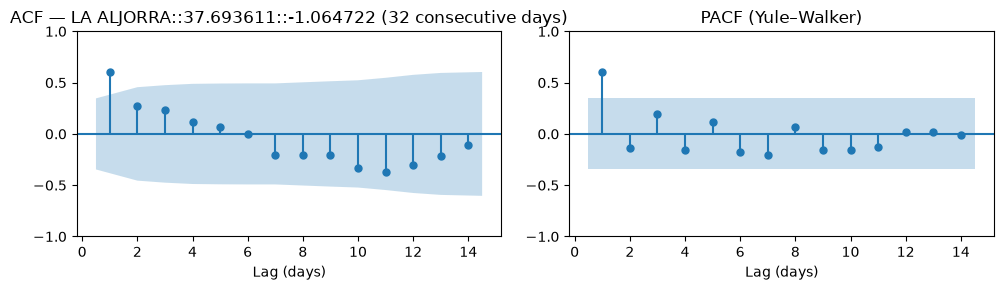

In [6]:
station = formal.sort_values("n_records", ascending=False).iloc[0]["node_id"]
series = (segments.loc[segments.station_id.eq(station)]
          .set_index("timestamp")["pm25"].sort_index())
max_lag = min(14, max(1, len(series) - 2))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.0))
plot_acf(series, lags=max_lag, ax=axes[0], zero=False)
axes[0].set(title=f"ACF — {station} ({len(series)} consecutive days)", xlabel="Lag (days)")
plot_pacf(series, lags=max_lag, method="ywm", ax=axes[1], zero=False)
axes[1].set(title="PACF (Yule–Walker)", xlabel="Lag (days)")
plt.tight_layout()
plt.show()

## 3. Trend slope per station

The OLS slope is estimated on elapsed days within each station's longest uninterrupted segment. A
positive slope means PM2.5 rises over that segment; the p-value tests a zero slope.

In [7]:
trend = diagnostics.loc[diagnostics.trend_slope_per_day.notna()].copy()
trend["significant_at_5pct"] = trend.trend_pval < 0.05
print(f"Stations with an estimable trend: {len(trend)}")
print(f"Negative slopes: {(trend.trend_slope_per_day < 0).sum()}; "
      f"positive slopes: {(trend.trend_slope_per_day > 0).sum()}; "
      f"significant at 5%: {int(trend.significant_at_5pct.sum())}")
print(f"Slope quantiles (µg/m³ per day): "
      f"{trend.trend_slope_per_day.quantile(0.05):.4f} (5%), "
      f"{trend.trend_slope_per_day.median():.4f} (median), "
      f"{trend.trend_slope_per_day.quantile(0.95):.4f} (95%)")
trend.sort_values("trend_slope_per_day")[["node_id", "n_records", "trend_slope_per_day", "trend_pval"]].head(10).reset_index(drop=True)

Stations with an estimable trend: 72
Negative slopes: 21; positive slopes: 51; significant at 5%: 25
Slope quantiles (µg/m³ per day): -0.3769 (5%), 0.0988 (median), 0.6107 (95%)


,node_id,n_records,trend_slope_per_day,trend_pval
0,VALLE DE ESCOMBRERAS::37.574400::-0.926543,9,-0.773993,0.119093
1,CASTELLÓ-PENYETA::40.012778::-0.057222,15,-0.528253,0.314934
2,VALÈNCIA-POLITÈCNIC::39.480300::-0.336400,20,-0.438108,0.002116
3,Sant Andreu de la Barca::41.450800::1.974900,9,-0.383333,0.627088
4,VALÈNCIA-PISTA DE SILLA::39.456111::-0.375833,20,-0.371574,0.000366
5,LOS BARRIOS::36.175380::-5.480830,15,-0.354338,0.023680
6,Barcelona - Porta - Can Dragó::41.431949::2.18...,14,-0.297580,0.242303
7,SAN BASILIO::37.992300::-1.145900,12,-0.296930,0.368462
8,RONDA SUR::37.970100::-1.127700,12,-0.200878,0.364560
9,VALÈNCIA - AVD. FRANCIA::39.457500::-0.342778,20,-0.176135,0.000853


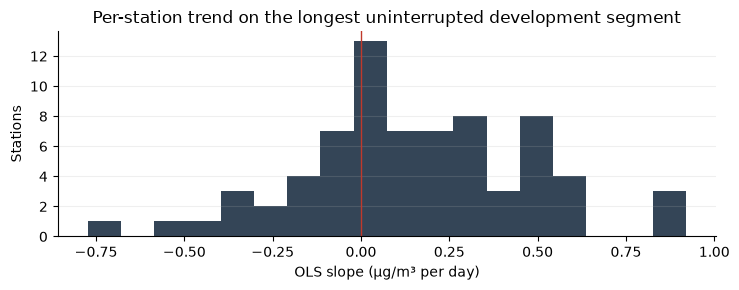

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 3.0))
ax.hist(trend.trend_slope_per_day, bins=18, color="#10243A", alpha=0.85)
ax.axvline(0, color="#C0392B", lw=1.0)
ax.set(xlabel="OLS slope (µg/m³ per day)", ylabel="Stations",
       title="Per-station trend on the longest uninterrupted development segment")
ax.grid(axis="y", alpha=0.2)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

## 4. Yearly drift and high-concentration frequency

The per-station diagnostics above describe local runs. This section aggregates the development
partition by calendar year to show whether the level and the frequency of high values drift over
time. The panel is unbalanced — the number of reporting stations changes every year — so the yearly
values are descriptive and are not used to estimate a trend.

 year  n_records  n_stations  mean  median  pct_gt_25  pct_gt_50
 2016        111          13 10.89   10.17       1.80       0.00
 2017       2116          17  9.46    7.67       3.83       0.33
 2018        252          18  7.88    7.02       0.40       0.00
 2019       1772          18  8.65    6.72       4.29       0.06
 2020       3247          22  7.55    5.71       2.06       0.09
 2021       4746          36  8.85    6.80       2.38       0.59
 2022       4954          39  9.62    8.12       2.02       0.46
 2023       5400          41 10.22    9.00       2.44       0.20
 2024       8053          54  9.56    7.96       2.93       0.21


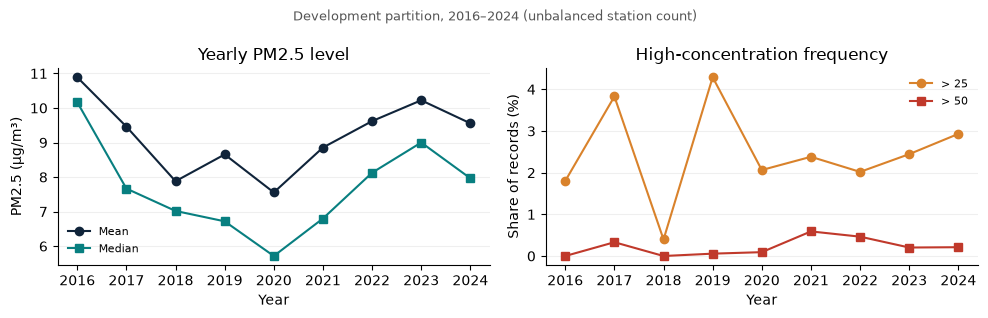

In [9]:
from pm25_project.relationships import yearly_table

yearly = yearly_table(development)
print(yearly[["year", "n_records", "n_stations", "mean", "median", "pct_gt_25", "pct_gt_50"]]
      .round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(yearly.year, yearly["mean"], marker="o", color="#10243A", label="Mean")
axes[0].plot(yearly.year, yearly["median"], marker="s", color="#087F80", label="Median")
axes[0].set(xlabel="Year", ylabel="PM2.5 (µg/m³)", title="Yearly PM2.5 level")
axes[0].legend(frameon=False, fontsize=8)
axes[1].plot(yearly.year, yearly.pct_gt_25, marker="o", color="#D9822B", label="> 25")
axes[1].plot(yearly.year, yearly.pct_gt_50, marker="s", color="#C0392B", label="> 50")
axes[1].set(xlabel="Year", ylabel="Share of records (%)", title="High-concentration frequency")
axes[1].legend(frameon=False, fontsize=8)
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
fig.suptitle(f"Development partition, {int(yearly.year.min())}–{int(yearly.year.max())} (unbalanced station count)",
             fontsize=9, color="#555555")
plt.tight_layout()
plt.show()